# Desafio 02 — Análise de Pedidos de Delivery

## 1. A base escolhida
Para esta análise, criei uma base de dados fictícia com registros de pedidos de um aplicativo de delivery (`dados/base.csv`). Informações: dia da semana, categoria da comida, presença de chuva, tempo de entrega (em minutos) e valor do pedido (em reais).

## 2. As perguntas investigadas
As três perguntas foram:

1. **Quais dias da semana concentram o maior volume de pedidos?**
   * *Por que importa:* Ajuda a planejar a escala de entregadores e evitar sobrecarga nos dias de pico.
2. **Qual categoria de comida gera o maior faturamento e qual tem o maior valor médio por pedido?**
   * *Por que importa:* Ajuda a equipe comercial e de marketing a decidir onde concentrar promoções e parcerias com restaurantes.
3. **O tempo de entrega é significativamente maior em dias de chuva do que em dias sem chuva?** *(Teste de hipótese)*
   * *Por que importa:* Permite ajustar a estimativa de prazo exibida no aplicativo quando está chovendo, reduzindo atrasos e reclamações de clientes.

## 3. Preparação dos dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Carregamento da base usando caminho relativo
df = pd.read_csv('dados/base.csv')

print(f"Tamanho da base original: {df.shape[0]} linhas e {df.shape[1]} colunas")
print("\nPrimeiras 5 linhas:")
display(df.head())

print("\nValores ausentes (nulos) por coluna:")
print(df.isnull().sum())

print("\nQuantidade de linhas duplicadas:", df.duplicated().sum())

Tamanho da base original: 508 linhas e 6 colunas

Primeiras 5 linhas:


,id_pedido,dia_semana,categoria,chuva,tempo_entrega_min,valor_pedido_rs
0,1,Quinta,Japonesa,Não,39.9,81.66
1,2,Domingo,Pizza,Não,31.3,74.96
2,3,Sábado,Pizza,Sim,34.9,77.98
3,4,Sexta,Brasileira,Sim,32.8,61.68
4,5,Terça,Japonesa,Sim,54.2,113.97



Valores ausentes (nulos) por coluna:
id_pedido             0
dia_semana            0
categoria             0
chuva                 0
tempo_entrega_min    11
valor_pedido_rs       8
dtype: int64

Quantidade de linhas duplicadas: 8


In [2]:
# Removendo duplicatas e linhas com valores ausentes nas colunas numéricas
df_limpo = df.drop_duplicates().copy()
df_limpo = df_limpo.dropna(subset=['tempo_entrega_min', 'valor_pedido_rs'])

print(f"Tamanho da base após limpeza: {df_limpo.shape[0]} linhas e {df_limpo.shape[1]} colunas")
print("\nConferindo valores ausentes após limpeza:")
print(df_limpo.isnull().sum())
print("\nConferindo duplicatas após limpeza:", df_limpo.duplicated().sum())
# Salvando a base limpa sem alterar o arquivo original
df_limpo.to_csv('dados/base_tratada.csv', index=False)
print("Base tratada salva em 'dados/base_tratada.csv'!")

Tamanho da base após limpeza: 482 linhas e 6 colunas

Conferindo valores ausentes após limpeza:
id_pedido            0
dia_semana           0
categoria            0
chuva                0
tempo_entrega_min    0
valor_pedido_rs      0
dtype: int64

Conferindo duplicatas após limpeza: 0
Base tratada salva em 'dados/base_tratada.csv'!


### Resumo do tratamento realizado
Na inspeção inicial da base original (508 linhas), foram encontrados:
- **8 linhas duplicadas**, que foram removidas com `drop_duplicates()` para não contar pedidos repetidos duas vezes.
- **Valores ausentes (nulos)** nas colunas `tempo_entrega_min` (11 registros) e `valor_pedido_rs` (8 registros). Como representam uma pequena fração da base e afetariam o cálculo de médias e do teste de hipótese, esses registros foram removidos com `dropna()`.

Após a limpeza, restaram **482 linhas válidas**, sem alterar o arquivo original salvo em `dados/base.csv`.

## 4. Análise, Estatística e Visualizações
Antes de responder às perguntas específicas, vamos observar as medidas estatísticas gerais (média, mediana, desvio padrão, mínimo e máximo) do tempo de entrega e do valor dos pedidos.

In [3]:
# Resumo estatístico geral das colunas numéricas
display(df_limpo[['tempo_entrega_min', 'valor_pedido_rs']].describe().round(2))

,tempo_entrega_min,valor_pedido_rs
count,482.00,482.00
mean,36.59,58.39
std,9.14,23.83
min,16.60,15.00
25%,30.20,39.75
50%,35.15,54.09
75%,41.70,76.99
max,62.50,126.45


,quantidade_pedidos
dia_semana,
Segunda,64
Terça,46
Quarta,48
Quinta,59
Sexta,82
Sábado,98
Domingo,85


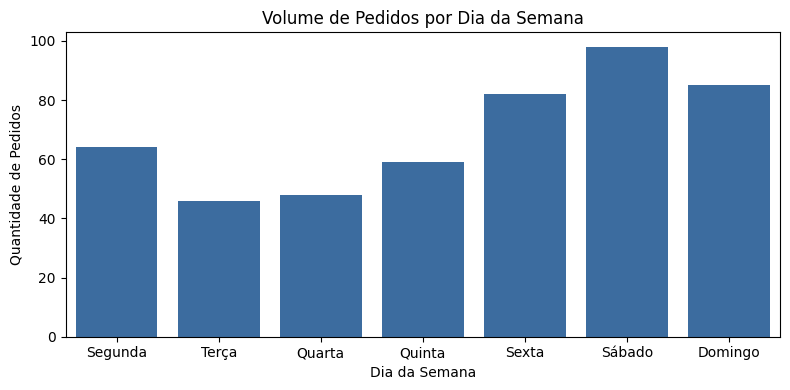

In [4]:
# Pergunta 1: Quais dias da semana concentram o maior volume de pedidos?
ordem_dias = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
pedidos_por_dia = df_limpo['dia_semana'].value_counts().reindex(ordem_dias)

display(pedidos_por_dia.to_frame(name='quantidade_pedidos'))

plt.figure(figsize=(8, 4))
sns.barplot(x=pedidos_por_dia.index, y=pedidos_por_dia.values, color='#2b6cb0')
plt.title('Volume de Pedidos por Dia da Semana')
plt.xlabel('Dia da Semana')
plt.ylabel('Quantidade de Pedidos')
plt.tight_layout()
plt.show()

**O que os dados revelam:**
O volume de pedidos cresce significativamente no fim de semana, com pico no **Sábado** (98 pedidos), seguido por **Domingo** e **Sexta**. Já os dias mais calmos são **Terça** e **Quarta**. Para o negócio, isso indica a necessidade de reforçar a escala de entregadores entre sexta e domingo.

,qtd_pedidos,faturamento_total,ticket_medio,mediana
categoria,,,,
Pizza,116,8360.66,72.07,72.65
Japonesa,78,7454.74,95.57,96.09
Lanches,159,6703.82,42.16,41.93
Brasileira,87,4284.81,49.25,49.82
Sobremesas,42,1339.52,31.89,31.26


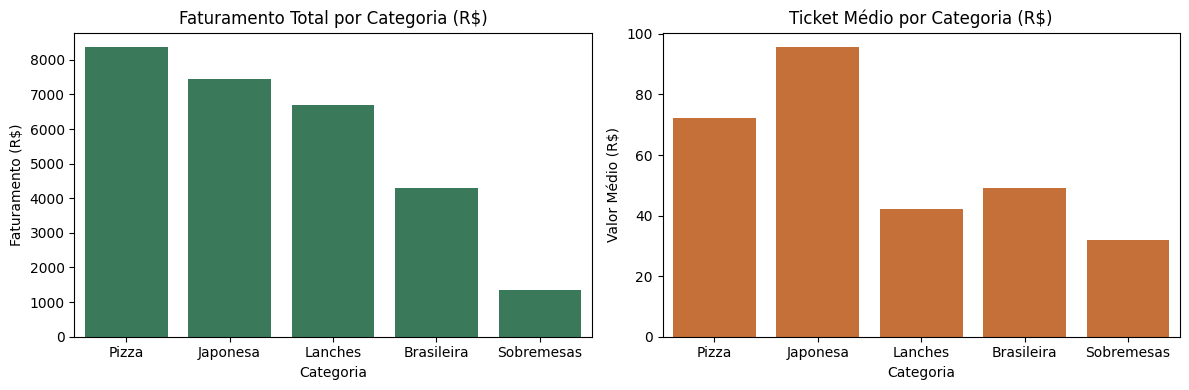

In [5]:
# Pergunta 2: Qual categoria gera o maior faturamento e qual tem maior valor médio?
resumo_cat = df_limpo.groupby('categoria')['valor_pedido_rs'].agg(
    qtd_pedidos='count',
    faturamento_total='sum',
    ticket_medio='mean',
    mediana='median'
).sort_values('faturamento_total', ascending=False).round(2)

display(resumo_cat)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=resumo_cat.index, y=resumo_cat['faturamento_total'], ax=axes[0], color='#2f855a')
axes[0].set_title('Faturamento Total por Categoria (R$)')
axes[0].set_xlabel('Categoria')
axes[0].set_ylabel('Faturamento (R$)')

sns.barplot(x=resumo_cat.index, y=resumo_cat['ticket_medio'], ax=axes[1], color='#dd6b20')
axes[1].set_title('Ticket Médio por Categoria (R$)')
axes[1].set_xlabel('Categoria')
axes[1].set_ylabel('Valor Médio (R$)')

plt.tight_layout()
plt.show()

**O que os dados revelam:**
A categoria líder em faturamento total são as **Pizzas**, somando **8.360,66** em vendas. Por outro lado, o maior ticket médio (valor gasto por pedido) pertence à categoria **Comida Japonesa**, com média de **95,57** por pedido. Isso mostra duas estratégias diferentes: uma categoria traz volume financeiro constante, enquanto outra traz alto valor por pedido individual.

## 5. Teste de Hipótese
**Pergunta:** O tempo de entrega é significativamente maior em dias de chuva do que em dias sem chuva?

- **Hipótese Nula ($H_0$):** Não há diferença real no tempo médio de entrega entre dias com chuva e dias sem chuva.
- **Hipótese Alternativa ($H_1$):** Há uma diferença real no tempo médio de entrega entre dias com chuva e dias sem chuva.
- **Nível de significância ($\alpha$):** 0,05 (5%).
-

,n,media,mediana,desvio_padrao
chuva,,,,
Não,329,32.13,31.9,5.74
Sim,153,46.18,46.5,7.59


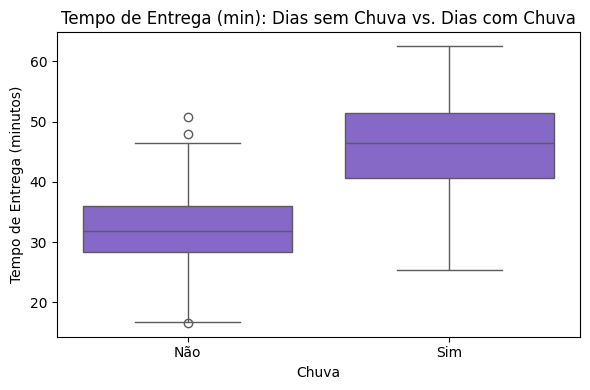

Estatística t: 20.3573
Valor-p: 7.189105e-54


In [6]:
# Separando os dois grupos
grupo_chuva = df_limpo[df_limpo['chuva'] == 'Sim']['tempo_entrega_min']
grupo_sem_chuva = df_limpo[df_limpo['chuva'] == 'Não']['tempo_entrega_min']

# Estatísticas de cada grupo
comparacao = df_limpo.groupby('chuva')['tempo_entrega_min'].agg(
    n='count',
    media='mean',
    mediana='median',
    desvio_padrao='std'
).round(2)
display(comparacao)

# Gráfico comparativo (Boxplot)
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_limpo, x='chuva', y='tempo_entrega_min', color='#805ad5')
plt.title('Tempo de Entrega (min): Dias sem Chuva vs. Dias com Chuva')
plt.xlabel('Chuva')
plt.ylabel('Tempo de Entrega (minutos)')
plt.tight_layout()
plt.show()

# Teste t de Welch para duas amostras independentes
estatistica_t, valor_p = stats.ttest_ind(grupo_chuva, grupo_sem_chuva, equal_var=False)
print(f"Estatística t: {estatistica_t:.4f}")
print(f"Valor-p: {valor_p:.6e}")

### Interpretação do Teste de Hipótese
Na comparação entre os dois grupos, observou-se:
- **Dias sem chuva (`Não`, n = 329):** média de **32,13 min** (mediana de **31,9 min** e desvio padrão de **5,74 min**).
- **Dias com chuva (`Sim`, n = 153):** média de **46,18 min** (mediana de **46,5 min** e desvio padrão de **7,59 min**).

O boxplot já evidencia uma separação clara entre as distribuições, com os pedidos em dias de chuva concentrados em tempos bem mais altos. Ao aplicar o teste t de Welch, obteve-se uma **estatística t = 20,3573** e um **valor-p = 7,19 × 10⁻⁵⁴** (muito abaixo do nível de significância α = 0,05).

**Resultado:** Rejeitamos a hipótese nula ($H_0$). Há forte evidência estatística de que o tempo médio de entrega é realmente maior em dias de chuva — cerca de **14 minutos a mais** na média — e que essa diferença não ocorreu por acaso.

## 6. Conclusões
A investigação dos 482 pedidos válidos permitiu responder às três perguntas de negócio:
1. **Dias de pico:** A demanda se concentra no fim de semana, liderada por **Sábado** (98 pedidos), indicando a necessidade de reforçar a equipe de entregadores nesses dias.
2. **Faturamento vs. ticket médio:** A categoria **Pizzas** gera o maior volume financeiro total (**8.360,66**), enquanto **Comida Japonesa** apresenta o maior gasto médio por pedido (**95,57**).
3. **Impacto da chuva nas entregas:** O teste de hipótese comprovou que entregas em dias de chuva demoram em média **14 minutos a mais** (46,18 min contra 32,13 min; valor-p < 0,05), justificando o ajuste automático do prazo exibido no aplicativo em dias chuvosos.

## 7. Reflexão
- **Python vs. Planilha:** Em Python, todo o processo de limpeza, geração de gráficos e execução do teste de hipótese fica registrado passo a passo em código. Se chegarem novos dados no futuro, basta rodar o notebook novamente para atualizar toda a análise em segundos, sem risco de quebrar fórmulas manualmente como ocorre em planilhas. Além disso, o teste estatístico (`ttest_ind`) e os gráficos comparativos ficam prontos com poucas linhas.
- **Organização do trabalho:** Este desafio foi desenvolvido de forma **individual**, conforme autorização do orientador. O fluxo foi organizado em etapas sequenciais: criação e preservação da base original, inspeção e limpeza dos dados, análise descritiva com gráficos, teste de hipótese e documentação final no repositório.